# G.657.A1 — Colab 광섬유 FEM 검증 보고서

**G.654.E와 같은 실행형 보고서 | LS PremierLink A1의 공개 MFD를 참고한 가상 단면 | 2026-10-19**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kimheeseo/LSCNS/blob/main/COMSOL/g657a1_validation/G657A1_Colab_Validation.ipynb)

`런타임 → 모두 실행`으로 실제 FEM·분산·수렴 계산과 그림을 다시 생성합니다. 저장된 출력도 바로 볼 수 있습니다.

**보정과 검증을 구분합니다.** 1310 nm의 MFD 9.2 µm를 가상 step-index 단면에 맞추는 것은 보정입니다. 실제 제품의 코어/trench 구조, 굽힘 손실, 감쇠, 케이블 컷오프 또는 ITU 적합성을 독립 검증한 결과가 아닙니다. 특히 G.657.A1의 핵심인 굽힘 손실은 현재 직선·실수 굴절률 솔버로 계산하지 않습니다.


## 1. 출처와 비교 기준

- [LS 2025 통신 브로셔, p.3](https://fliphtml5.com/plzsm/rgkq/20250925_%ED%86%B5%EC%8B%A0_%EB%B8%8C%EB%A1%9C%EC%85%94/): PremierLink A1/A2의 MFD 9.2 µm @1310 nm와 감쇠 ≤0.18 dB/km @1550 nm를 공개합니다. A1만의 내부 구조나 굽힘 실측값으로 해석하지 않습니다.
- [ITU-T G.657 (08/2024), Table 1](https://www.itu.int/epublications/publication/itu-t-g-657-2024-08-characteristics-of-a-bending-loss-insensitive-single-mode-optical-fibre-and-cable): G.657.A1 참조값을 사용합니다. A2/B3와 구분합니다.

| 비교 항목 | G.657.A / A1 기준 | 이번 처리 |
|---|---|---|
| 명목 MFD @1310 nm | 8.6–9.2 µm, 공차 ±0.4 µm | 9.2 µm를 **보정 목표**로 선택 |
| λ0 / S0 | 1300–1324 nm / 0.073–0.092 ps/(nm²·km) | 모델 예측의 참고 비교 |
| D1550 / D1625 | 13.3–18.6 / 17.2–23.7 ps/(nm·km) | 모델 예측의 참고 비교 |
| 케이블 컷오프 | ≤1260 nm | 이상적 LP11 컷오프와 동일시 금지 |
| R=15 mm, 10회: 1550/1625 nm | ≤0.25 / ≤1.0 dB | **계산 불가** |
| R=10 mm, 1회: 1550/1625 nm | ≤0.75 / ≤1.5 dB | **계산 불가** |

MFD는 Petermann-II와 second-moment를 따로 표시합니다. 물질 모델은 실리카 Sellmeier + 일정 Δn이며 실제 도핑 분산·trench를 포함하지 않습니다.


In [1]:
# @title 2. 실행 환경 확인
import sys, json, platform, zipfile, uuid, hashlib
from pathlib import Path
from dataclasses import replace
from datetime import datetime, timezone
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
get_ipython().run_line_magic('matplotlib','inline')
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
RESULT_DIR=Path('G657A1_Colab_Results')/RUN_ID
RESULT_DIR.mkdir(parents=True,exist_ok=False)
print('Python',sys.version.split()[0],'NumPy',np.__version__,'SciPy',scipy.__version__)
print('실행마다 별도 결과 폴더:',RESULT_DIR)


No event loop hook running.
Python 3.12.14 NumPy 2.3.5 SciPy 1.17.0
실행마다 별도 결과 폴더: G657A1_Colab_Results/20261019T055628_8ae7b695


In [2]:
# @title 3. 파라미터 입력
wavelength_nm = 1310.0 # @param {type:"number"}
core_radius_um = 4.1 # @param {type:"number"}
reference_mfd_um = 9.2 # @param {type:"number"}
mfd_reference_wavelength_nm = 1310.0  # 카탈로그 MFD의 파장: 분석 파장과 별개
fit_delta_n_from_mfd = True # @param {type:"boolean"}
delta_n_if_not_fitting = 0.004621529545 # @param {type:"number"}
outer_radius_um = 40.0 # @param {type:"number"}
run_2d_fem = True # @param {type:"boolean"}
run_profile_sensitivity = True # @param {type:"boolean"}
n2_m2_per_W = 2.6e-20 # @param {type:"number"}
assert 1260<=wavelength_nm<=1625
assert 0<core_radius_um<outer_radius_um/2 and reference_mfd_um>0
assert outer_radius_um>=30 and n2_m2_per_W>0
print('MFD는 1310 nm에서 보정합니다. 분석 파장을 바꿔도 이 기준 파장은 유지됩니다.')


MFD는 1310 nm에서 보정합니다. 분석 파장을 바꿔도 이 기준 파장은 유지됩니다.


## 4. 수치해석 엔진

Bessel LP01 해석해, 경계 정합 radial P1 FEM, 기존 M7 방식의 2D 삼각형 P1 FEM을 노트북에 포함했습니다. 외부 저장소 다운로드 없이 실행할 수 있습니다. Aeff·second-moment MFD는 장 적분으로 계산합니다. LP01 해석해의 지원 범위는 V<2.405이며, 범위를 벗어난 설정은 오류로 알립니다.


In [3]:
# @title 4-1. Bessel / Radial / 2D FEM 엔진 (펼쳐보기)
"""Independent repeatable verification of the M7 scalar Step-index assumptions.
Numerical radial P1 FEM is directly transcribed from COMSOL/waveoptics_m7/src/radial_fem.py
(with equivalent input class). LP01 Bessel oracle is transcribed from fiber_modes.py.
This DOES NOT simulate or validate the actual undisclosed G.657.A1 index profile.
"""
from __future__ import annotations
from dataclasses import dataclass, replace
import numpy as np
from scipy.special import j0,j1,k0 as K0,k1 as K1
from scipy.optimize import brentq, root, minimize_scalar
from scipy.integrate import quad
from numpy.polynomial.legendre import leggauss
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh
import matplotlib.pyplot as plt
import json
from pathlib import Path
C0=299792458.
SB=(.6961663,.4079426,.8974794);SC=(.0684043**2,.1162414**2,9.896161**2)
def silica_index(w):
 w=float(w)
 return float(np.sqrt(1+sum(b*w*w/(w*w-c) for b,c in zip(SB,SC))))
@dataclass(frozen=True)
class Fiber:
 wavelength_um:float=1.31
 radius_um:float=4.1
 delta_n:float=.003
 domain_halfwidth_um:float=35.
 n_cladding:float|None=None
 @property
 def clad(self):return silica_index(self.wavelength_um) if self.n_cladding is None else self.n_cladding
 @property
 def core(self):return self.clad+self.delta_n
 @property
 def v(self):return 2*np.pi*self.radius_um/self.wavelength_um*np.sqrt(self.core**2-self.clad**2)
def lp01_analytic(f):
 v=f.v
 if not 0<v<2.404825557695772:raise ValueError(f"LP01 oracle limited V<2.405: V={v}")
 def eq(u):
  w=np.sqrt(v*v-u*u)
  return u*j1(u)/j0(u)-w*K1(w)/K0(w)
 u=brentq(eq,max(v*1e-6,1e-8),v*(1-1e-10),xtol=2e-13)
 w=np.sqrt(v*v-u*u)
 ne=float(np.sqrt((2*np.pi*f.core/f.wavelength_um)**2-(u/f.radius_um)**2)*f.wavelength_um/(2*np.pi))
 return dict(V=float(v),u=float(u),w=float(w),n_eff=ne)
def radial_lp01_aeff(f):
 a=lp01_analytic(f);u,w=a['u'],a['w'];radius=f.radius_um
 def shape(t):return j0(u*t)/j0(u) if t<=1 else K0(w*t)/K0(w)
 def d_shape(t):return -u*j1(u*t)/j0(u) if t<=1 else -w*K1(w*t)/K0(w)
 def integrate(power,moment,deriv=False):
  s=d_shape if deriv else shape
  fun=lambda t:s(t)**power*t**moment
  return quad(fun,0,1,epsabs=1e-11,epsrel=1e-10)[0]+quad(fun,1,np.inf,epsabs=1e-11,epsrel=1e-10)[0]
 total=2*np.pi*radius**2*integrate(2,1)
 four=2*np.pi*radius**2*integrate(4,1)
 mom=2*np.pi*radius**4*integrate(2,3)/total
 # Petermann-II: MFD=2 sqrt(2 * \int E^2 r dr / \int (dE/dr)^2 r dr).
 # With t=r/a, denominator has no a^2 and numerator has a^2.
 petermann=2*radius*np.sqrt(2*integrate(2,1)/integrate(2,1,deriv=True))
 return dict(Aeff_um2=float(total**2/four),MFD_2nd_um=float(2*np.sqrt(2*mom)), MFD_petermann_ii_um=float(petermann))
def solve_radial(fiber, core_elements=160, clad_elements=640, outer_radius_um=None):
 outer = fiber.domain_halfwidth_um if outer_radius_um is None else float(outer_radius_um)
 a=fiber.radius_um
 r=np.r_[np.linspace(0,a,core_elements+1),np.linspace(a,outer,clad_elements+1)[1:]]
 x,w=leggauss(4);t=(x+1)/2;phi=np.stack((1-t,t),axis=1)
 h=np.diff(r);rq=r[:-1,None]+h[:,None]*t;weights=h[:,None]*w/2
 mass=np.einsum('eq,qi,qj->eij',weights*rq,phi,phi)
 stiff=((r[1:]**2-r[:-1]**2)/(2*h**2))[:,None,None]*np.array([[1.,-1.],[-1.,1.]])
 indices=np.r_[np.full(core_elements,fiber.core),np.full(clad_elements,fiber.clad)]
 k0=2*np.pi/fiber.wavelength_um
 local=k0**2*indices[:,None,None]**2*mass-stiff
 edges=np.stack((np.arange(len(h)),np.arange(len(h))+1),axis=1)
 rows=np.broadcast_to(edges[:,:,None],local.shape).ravel()
 cols=np.broadcast_to(edges[:,None,:],local.shape).ravel()
 def matrix(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(r),len(r))).tocsr()[:-1,:-1]
 A,M=matrix(local),matrix(mass)
 val,vec=eigsh(A,k=1,M=M,sigma=(k0*fiber.core)**2,which='LM',v0=np.ones(len(r)-1),tol=1e-11)
 beta2=float(val[0]);q=vec[:,0]
 residual=np.linalg.norm(A@q-beta2*(M@q))/np.linalg.norm(beta2*(M@q))
 field=np.r_[q,0.]
 if field[0]<0:field=-field
 fieldq=field[edges]@phi.T;intensity=fieldq**2
 wt=2*np.pi*weights*rq;power=np.sum(wt*intensity)
 aeff=power**2/np.sum(wt*intensity**2)
 moment=np.sum(wt*intensity*rq**2)/power
 neff=np.sqrt(beta2)/k0 if beta2>0 else float('nan')
 return dict(n_eff=float(neff),Aeff_um2=float(aeff),MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(residual),guided=bool(fiber.clad<neff<fiber.core),outer_radius_um=outer,core_elements=core_elements,clad_elements=clad_elements, radius_um=r,field=field/np.sqrt(power))
def dispersion_lp01(f,step=.003):
 def ne(x):return lp01_analytic(replace(f,wavelength_um=float(x)))['n_eff']
 w=f.wavelength_um;h=step
 d2=(-ne(w+2*h)+16*ne(w+h)-30*ne(w)+16*ne(w-h)-ne(w-2*h))/(12*h*h)
 return float(-(w/C0)*1e12*d2)

def grid(n,h):
 if not isinstance(n,(int,np.integer)) or isinstance(n,bool) or n<15 or n%2!=1:raise ValueError('odd mesh count>=15')
 if not np.isfinite(h) or h<=0:raise ValueError('positive finite halfwidth')
 xy=np.stack(np.meshgrid(np.linspace(-h,h,n),np.linspace(-h,h,n),indexing='xy'),-1).reshape(-1,2)
 i,j=np.meshgrid(np.arange(n-1),np.arange(n-1),indexing='xy');p=(j*n+i).ravel()
 tris=np.concatenate([np.stack([p,p+1,p+n+1],1),np.stack([p,p+n+1,p+n],1)]).astype(int)
 free=np.flatnonzero((np.abs(xy[:,0])<h-1e-9)&(np.abs(xy[:,1])<h-1e-9))
 return xy,tris,free
def assemble_fem(xy,tri,index):
 p=xy[tri];dx=p[:,1,0]-p[:,0,0];dy=p[:,1,1]-p[:,0,1];ex=p[:,2,0]-p[:,0,0];ey=p[:,2,1]-p[:,0,1]
 det=dx*ey-dy*ex
 if np.any(np.abs(det)<1e-14):raise ValueError('degenerate triangle')
 area=np.abs(det)/2
 gx=np.stack([p[:,1,1]-p[:,2,1],p[:,2,1]-p[:,0,1],p[:,0,1]-p[:,1,1]],1)/det[:,None]
 gy=np.stack([p[:,2,0]-p[:,1,0],p[:,0,0]-p[:,2,0],p[:,1,0]-p[:,0,0]],1)/det[:,None]
 K=area[:,None,None]*(gx[:,:,None]*gx[:,None,:]+gy[:,:,None]*gy[:,None,:])
 b=np.ones((3,3));np.fill_diagonal(b,2)
 M=area[:,None,None]*b[None,:,:]/12
 ni=np.asarray(index(p.mean(1)),float)
 if len(ni)!=len(area) or np.any(ni<=0):raise ValueError('invalid index')
 N=M*ni[:,None,None]**2
 rows=np.broadcast_to(tri[:,:,None],(len(tri),3,3)).ravel()
 cols=np.broadcast_to(tri[:,None,:],(len(tri),3,3)).ravel()
 def csr(v):return coo_matrix((v.ravel(),(rows,cols)),shape=(len(xy),len(xy))).tocsr()
 return csr(K),csr(M),csr(N)
def solve_modes(f,n=81,cores=None,modes=2):
 centers=[(0.,0.)] if cores is None else list(cores)
 c=np.asarray(centers,float)
 xy,tri,free=grid(n,f.domain_halfwidth_um)
 def index(points):
  r2=np.full(len(points),np.inf)
  for xx,yy in centers:r2=np.minimum(r2,(points[:,0]-xx)**2+(points[:,1]-yy)**2)
  return np.where(r2<=f.radius_um**2,f.core,f.clad)
 K,M,N=assemble_fem(xy,tri,index);k0=2*np.pi/f.wavelength_um;A=(k0*k0*N-K)[free][:,free];MM=M[free][:,free]
 vals,vectors=eigsh(A,k=modes,M=MM,sigma=(k0*f.core)**2+.02,which='LM',tol=1e-10,v0=np.random.default_rng(0).normal(size=len(free)))
 order=np.argsort(vals)[::-1];vals=vals[order];vectors=vectors[:,order]
 fields=np.zeros((len(xy),modes));fields[free,:]=vectors
 neff=np.sqrt(np.maximum(0,vals))/k0
 resid=[float(np.linalg.norm(A@vectors[:,i]-vals[i]*(MM@vectors[:,i]))/np.linalg.norm(vals[i]*(MM@vectors[:,i]))) for i in range(modes)]
 return dict(fiber=f,n=n,xy=xy,triangles=tri,free=free,mass=M,neff=neff,fields=fields,guided=(neff>f.clad)&(neff<f.core),residuals=resid,cores=centers)
def scalar_metrics(sol,k=0):
 b=np.array([[1/3,1/3,1/3],[.059715871789770,.470142064105115,.470142064105115],[.470142064105115,.059715871789770,.470142064105115],[.470142064105115,.470142064105115,.059715871789770],[.797426985353087,.101286507323456,.101286507323456],[.101286507323456,.797426985353087,.101286507323456],[.101286507323456,.101286507323456,.797426985353087]])
 weights=np.array([.225,.132394152788506,.132394152788506,.132394152788506,.125939180544827,.125939180544827,.125939180544827])
 tri=sol['triangles'];xyz=sol['xy'][tri];p=sol['fields'][tri,k]
 area=np.abs((xyz[:,1,0]-xyz[:,0,0])*(xyz[:,2,1]-xyz[:,0,1])-(xyz[:,2,0]-xyz[:,0,0])*(xyz[:,1,1]-xyz[:,0,1]))/2
 intensity=np.abs(p@b.T)**2;points=np.einsum('qi,tij->tqj',b,xyz)
 wt=area[:,None]*weights
 power=float(np.sum(wt*intensity));four=float(np.sum(wt*intensity**2))
 center=np.sum(wt[:,:,None]*intensity[:,:,None]*points,axis=(0,1))/power
 r2=np.sum((points-center)**2,axis=2);moment=np.sum(wt*intensity*r2)/power
 return dict(n_eff=float(sol['neff'][k]),Aeff_um2=power**2/four,MFD_2nd_um=float(2*np.sqrt(2*moment)),residual=float(sol['residuals'][k]),centroid_um=center.tolist(),power_integral=power)



In [4]:
# @title 5. MFD 보정과 분석 파장별 결과
LAMBDA_UM=wavelength_nm/1000.
def calibrated_fiber(radius_um=core_radius_um, target_mfd_um=reference_mfd_um):
    refwl=mfd_reference_wavelength_nm/1000.
    def deviation(dn):
        t=Fiber(wavelength_um=refwl,radius_um=radius_um,delta_n=float(dn),domain_halfwidth_um=outer_radius_um)
        if not .8<t.v<2.4047:return np.nan
        return radial_lp01_aeff(t)['MFD_petermann_ii_um']-target_mfd_um
    trial=[(float(x),deviation(x)) for x in np.linspace(.0005,.008,120)]
    trial=[x for x in trial if np.isfinite(x[1])]
    bracket=next(((x[0],y[0]) for x,y in zip(trial,trial[1:]) if x[1]*y[1]<0),None)
    if bracket is None:raise ValueError('보정해를 찾지 못했습니다: 코어 반경/MFD를 지원 범위에서 조정하세요.')
    dn=brentq(deviation,*bracket,xtol=1e-13)
    return Fiber(wavelength_um=LAMBDA_UM,radius_um=radius_um,delta_n=float(dn),domain_halfwidth_um=outer_radius_um)
f=calibrated_fiber() if fit_delta_n_from_mfd else Fiber(wavelength_um=LAMBDA_UM,radius_um=core_radius_um,delta_n=delta_n_if_not_fitting,domain_halfwidth_um=outer_radius_um)
ref=lp01_analytic(f);metrics=radial_lp01_aeff(f)
f1310=replace(f,wavelength_um=1.31);f1550=replace(f,wavelength_um=1.55);f1625=replace(f,wavelength_um=1.625)
m1310=radial_lp01_aeff(f1310);m1550=radial_lp01_aeff(f1550)
D_at1550=dispersion_lp01(f1550);D_at1625=dispersion_lp01(f1625)
zero_nm=brentq(lambda w:dispersion_lp01(replace(f,wavelength_um=w)),1.28,1.36,xtol=1e-9)*1000
fz=replace(f,wavelength_um=zero_nm/1000)
S0=(dispersion_lp01(replace(fz,wavelength_um=fz.wavelength_um+.005))-dispersion_lp01(replace(fz,wavelength_um=fz.wavelength_um-.005)))/10
cutoff_proxy_nm=mfd_reference_wavelength_nm*f1310.v/2.4048255577
gamma1550=2*np.pi*n2_m2_per_W/(1.55e-6*m1550['Aeff_um2']*1e-12)*1000
results=dict(analysis_wavelength_nm=wavelength_nm,MFD_reference_wavelength_nm=1310.,MFD_target_um=reference_mfd_um,
 assumed_core_radius_um=f.radius_um,fitted_delta_n=f.delta_n,n_clad=f.clad,n_core=f.core,V=f.v,
 neff_analytic=ref['n_eff'],**metrics,MFD_PII_1310_um=m1310['MFD_petermann_ii_um'],
 MFD_PII_1550_um=m1550['MFD_petermann_ii_um'],Aeff_1550_um2=m1550['Aeff_um2'],
 lambda0_nm=zero_nm,S0_ps_nm2_km=S0,D1550_ps_nm_km=D_at1550,D1625_ps_nm_km=D_at1625,
 ideal_LP11_cutoff_proxy_nm=cutoff_proxy_nm,n2_assumed_m2_W=n2_m2_per_W,gamma1550_W_inv_km_inv=gamma1550,
 MFD_was_fitted=fit_delta_n_from_mfd)
display(pd.DataFrame({'계산값':results}).rename_axis('항목'))
print('MFD 보정은 독립 검증이 아닙니다. gamma는 입력 n2와 예측 Aeff를 사용한 파생값입니다.')


MFD 보정은 독립 검증이 아닙니다. gamma는 입력 n2와 예측 Aeff를 사용한 파생값입니다.


                                     계산값
항목                                      
analysis_wavelength_nm            1310.0
MFD_reference_wavelength_nm       1310.0
MFD_target_um                        9.2
assumed_core_radius_um               4.1
fitted_delta_n                  0.004622
n_clad                          1.446804
n_core                          1.451426
V                               2.275892
neff_analytic                   1.449108
Aeff_um2                       66.267872
MFD_2nd_um                      9.420343
MFD_petermann_ii_um                  9.2
MFD_PII_1310_um                      9.2
MFD_PII_1550_um                10.543027
Aeff_1550_um2                  84.459523
lambda0_nm                   1303.281398
S0_ps_nm2_km                    0.084042
D1550_ps_nm_km                 16.641833
D1625_ps_nm_km                 20.687858
ideal_LP11_cutoff_proxy_nm   1239.765222
n2_assumed_m2_W                      0.0
gamma1550_W_inv_km_inv           1.24788
MFD_was_fitted  

## 6. 모드 분포와 가정한 굴절률 구조

첫 번째 2D 그림은 Bessel 해석해입니다. 실제 2D FEM 필드는 뒤에서 별도로 계산합니다. 굽힘 방사손실·코팅·trench는 포함되지 않습니다.


<Figure size 600x500 with 2 Axes>

<Figure size 600x300 with 1 Axes>

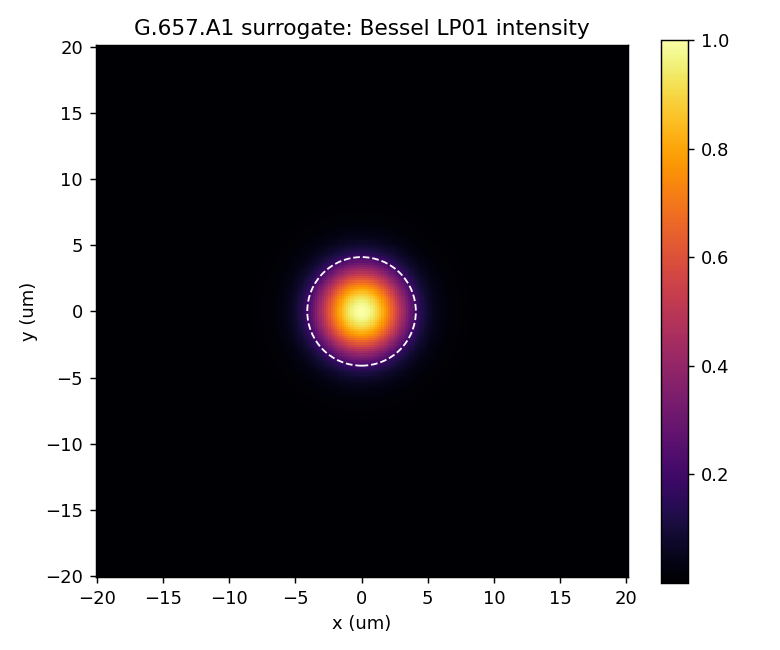

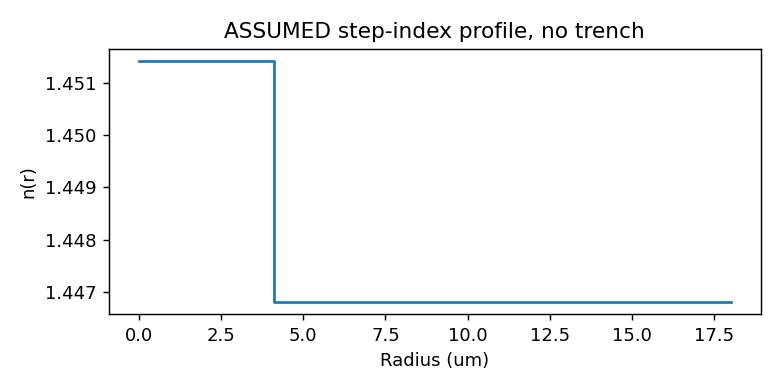

In [5]:
# @title 6-1. Bessel 모드 및 굴절률 단면
xx=np.linspace(-20,20,240);X,Y=np.meshgrid(xx,xx);R=np.hypot(X,Y)
u,w=ref['u'],ref['w']
E=np.where(R<=f.radius_um,j0(u*R/f.radius_um)/j0(u),K0(w*np.maximum(R,1e-9)/f.radius_um)/K0(w))
fig,ax=plt.subplots(figsize=(6,5));im=ax.pcolormesh(X,Y,E**2/np.max(E**2),shading='auto',cmap='inferno')
ax.add_patch(plt.Circle((0,0),f.radius_um,fill=False,edgecolor='white',ls='--'))
ax.set(xlabel='x (um)',ylabel='y (um)',title='G.657.A1 surrogate: Bessel LP01 intensity',aspect='equal');fig.colorbar(im,ax=ax)
fig.tight_layout();fig.savefig(RESULT_DIR/'01_LP01_Bessel_Field.png',dpi=130);plt.show()
rr=np.linspace(0,18,400);fig,ax=plt.subplots(figsize=(6,3))
ax.step(rr,np.where(rr<=f.radius_um,f.core,f.clad),where='post');ax.set(xlabel='Radius (um)',ylabel='n(r)',title='ASSUMED step-index profile, no trench')
fig.tight_layout();fig.savefig(RESULT_DIR/'02_Index_Profile.png',dpi=130);plt.show()


   elements  outer_radius_um  ...  MFD_error_pct      residual
0       200             40.0  ...       0.021398  8.584935e-16
1       400             40.0  ...       0.005349  3.230515e-15
2       800             40.0  ...       0.001337  1.214054e-14
3      1600             40.0  ...       0.000334  4.866024e-14

[4 rows x 9 columns]

<Figure size 600x380 with 1 Axes>

<Figure size 600x380 with 1 Axes>

   outer_radius_um     n_eff   Aeff_um2  MFD_2nd_um      residual
0             30.0  1.449108  66.268482    9.420390  4.573507e-14
1             40.0  1.449108  66.268484    9.420392  4.497732e-14
2             50.0  1.449108  66.268483    9.420392  5.015166e-14

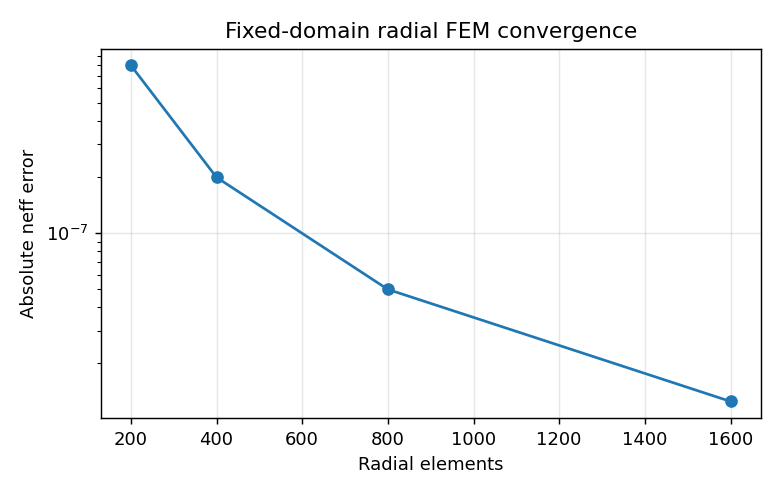

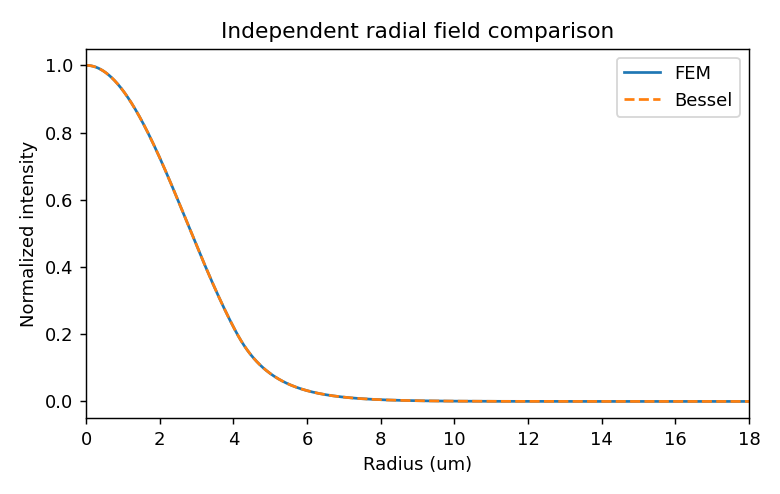

In [6]:
# @title 7. Radial FEM 메시와 영역 크기를 별도로 검사
radial_rows=[];radial_solution=None
for nc,ns in [(40,160),(80,320),(160,640),(320,1280)]:
    sol=solve_radial(f,core_elements=nc,clad_elements=ns,outer_radius_um=outer_radius_um)
    radial_solution=sol
    radial_rows.append(dict(elements=nc+ns,outer_radius_um=outer_radius_um,neff_FEM=sol['n_eff'],neff_abs_error=abs(sol['n_eff']-ref['n_eff']),
     Aeff_um2=sol['Aeff_um2'],Aeff_error_pct=100*(sol['Aeff_um2']/metrics['Aeff_um2']-1),MFD_second_um=sol['MFD_2nd_um'],
     MFD_error_pct=100*(sol['MFD_2nd_um']/metrics['MFD_2nd_um']-1),residual=sol['residual']))
radial_df=pd.DataFrame(radial_rows);display(radial_df)
fig,ax=plt.subplots(figsize=(6,3.8));ax.semilogy(radial_df.elements,radial_df.neff_abs_error,'o-')
ax.set(xlabel='Radial elements',ylabel='Absolute neff error',title='Fixed-domain radial FEM convergence');ax.grid(alpha=.3)
fig.tight_layout();fig.savefig(RESULT_DIR/'03_Radial_Mesh_Convergence.png',dpi=130);plt.show()
rr=radial_solution['radius_um'];field=radial_solution['field'];oracle=np.where(rr<=f.radius_um,j0(ref['u']*rr/f.radius_um)/j0(ref['u']),K0(ref['w']*np.maximum(rr,1e-9)/f.radius_um)/K0(ref['w']))
fig,ax=plt.subplots(figsize=(6,3.8));ax.plot(rr,field**2/max(field**2),label='FEM');ax.plot(rr,oracle**2/max(oracle**2),'--',label='Bessel')
ax.set(xlabel='Radius (um)',ylabel='Normalized intensity',title='Independent radial field comparison');ax.set_xlim(0,18);ax.legend()
fig.tight_layout();fig.savefig(RESULT_DIR/'04_Radial_Field_Comparison.png',dpi=130);plt.show()
domain_rows=[]
for outer in [30.,40.,50.]:
    sol=solve_radial(f,core_elements=320,clad_elements=int(np.ceil((outer-f.radius_um)/.035)),outer_radius_um=outer)
    domain_rows.append({k:sol[k] for k in ['outer_radius_um','n_eff','Aeff_um2','MFD_2nd_um','residual']})
domain_df=pd.DataFrame(domain_rows);display(domain_df)


## 8. G.657.A용 분산 비교

1260–1625 nm의 모델 D를 계산하고, 규격 표의 1550/1625 nm 경계값을 각각 비교합니다. 전 파장 합격으로 확장하지 않습니다. λ0·S0는 보정에 쓰지 않은 모델 예측이지만, 실제 제조사 측정값과의 대조는 아닙니다.


D1550: 16.641833358947995 D1625: 20.687858000759007 lambda0: 1303.2813980824003 S0: 0.08404163559534177
D1550 finite-difference steps: {'0.006': 16.641833494478686, '0.003': 16.641833358947995, '0.0015': 16.641831945176875}


<Figure size 740x400 with 1 Axes>

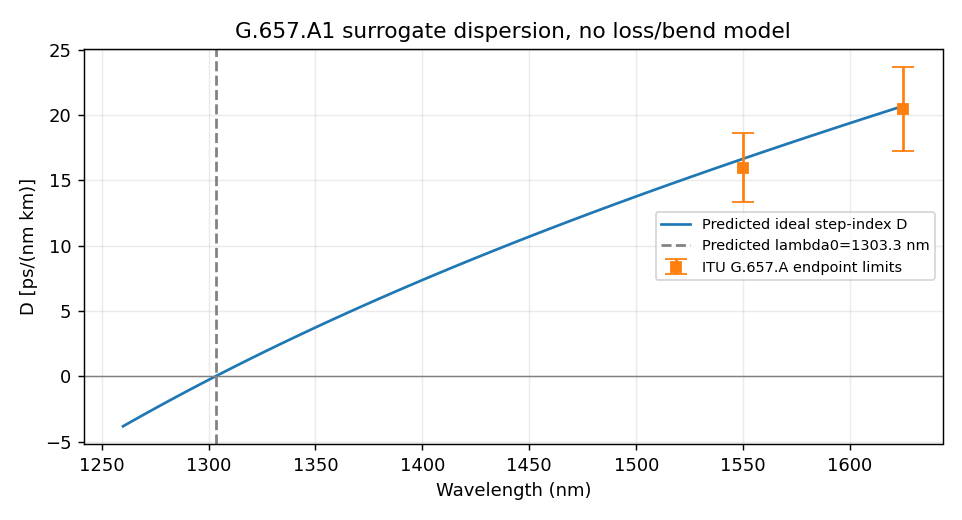

In [7]:
# @title 8-1. 분산 곡선, 영분산 파장 및 도함수 간격 검사
lambdas_nm=np.linspace(1260,1625,75)
Dvals=np.array([dispersion_lp01(replace(f,wavelength_um=float(x)/1000)) for x in lambdas_nm])
Dband_df=pd.DataFrame({'wavelength_nm':lambdas_nm,'D_model_ps_nm_km':Dvals})
fig,ax=plt.subplots(figsize=(7.4,4));ax.plot(lambdas_nm,Dvals,label='Predicted ideal step-index D')
ax.errorbar([1550,1625],[(13.3+18.6)/2,(17.2+23.7)/2],yerr=[(18.6-13.3)/2,(23.7-17.2)/2],fmt='s',capsize=6,label='ITU G.657.A endpoint limits')
ax.axhline(0,color='gray',lw=.8);ax.axvline(zero_nm,ls='--',color='gray',label=f'Predicted lambda0={zero_nm:.1f} nm')
ax.set(xlabel='Wavelength (nm)',ylabel='D [ps/(nm km)]',title='G.657.A1 surrogate dispersion, no loss/bend model');ax.legend(fontsize=8);ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(RESULT_DIR/'05_Dispersion_ITU_Checkpoints.png',dpi=130);plt.show()
disp_steps={str(h):dispersion_lp01(f1550,step=h) for h in [.006,.003,.0015]}
print('D1550:',D_at1550,'D1625:',D_at1625,'lambda0:',zero_nm,'S0:',S0)
print('D1550 finite-difference steps:',disp_steps)


   grid_n  triangles  ...  MFD_second_error_pct      residual
0      61       7200  ...              0.862125  1.733413e-16
1      81      12800  ...              0.563191  1.807777e-16
2     121      28800  ...              0.142431  1.036441e-15
3     161      51200  ...              0.054644  5.369733e-16

[4 rows x 9 columns]

<Figure size 600x380 with 1 Axes>

<Figure size 600x500 with 2 Axes>

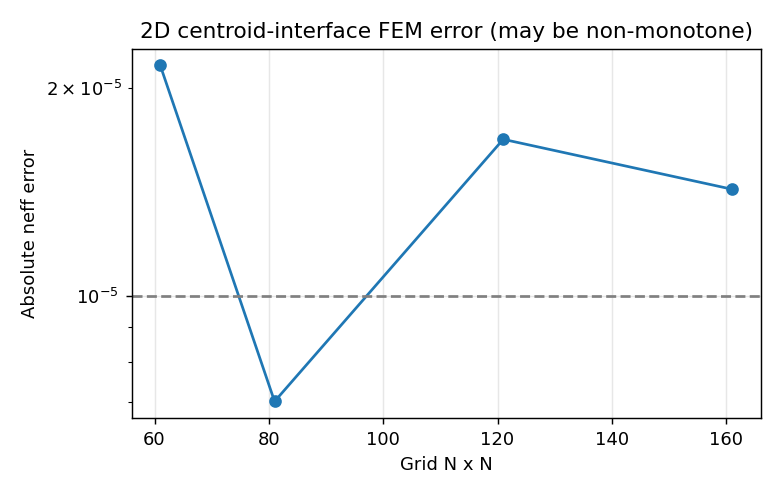

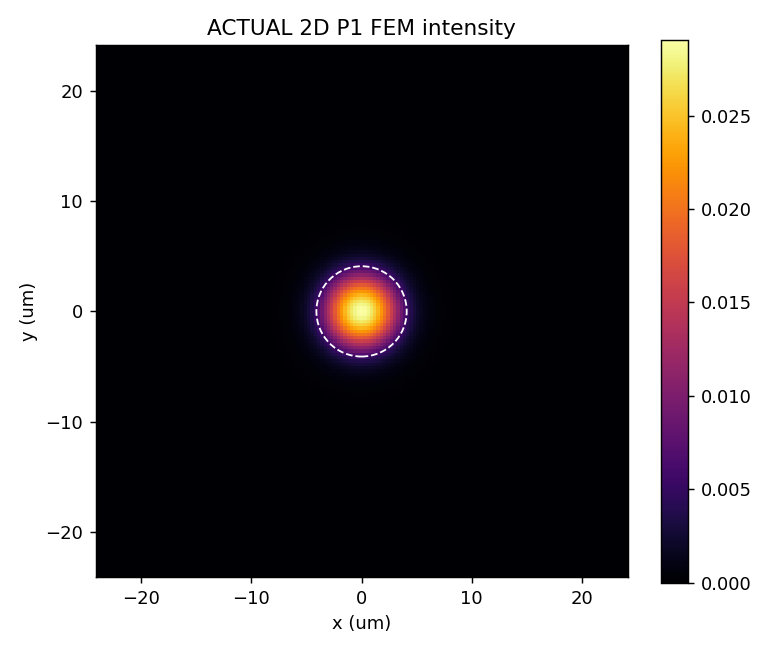

In [8]:
# @title 9. 2D FEM 실제 재계산 및 필드
records=[];fem2d_df=pd.DataFrame()
if run_2d_fem:
    f2d=replace(f,domain_halfwidth_um=24.)
    for n in [61,81,121,161]:
        sol=solve_modes(f2d,n=n,modes=1);met=scalar_metrics(sol)
        records.append(dict(grid_n=n,triangles=len(sol['triangles']),neff_FEM=met['n_eff'],neff_abs_error=abs(met['n_eff']-ref['n_eff']),
         Aeff_um2=met['Aeff_um2'],Aeff_error_pct=100*(met['Aeff_um2']/metrics['Aeff_um2']-1),MFD_second_um=met['MFD_2nd_um'],
         MFD_second_error_pct=100*(met['MFD_2nd_um']/metrics['MFD_2nd_um']-1),residual=met['residual']))
    fem2d_df=pd.DataFrame(records);display(fem2d_df)
    fig,ax=plt.subplots(figsize=(6,3.8));ax.semilogy(fem2d_df.grid_n,fem2d_df.neff_abs_error,'o-');ax.axhline(1e-5,ls='--',color='gray')
    ax.set(xlabel='Grid N x N',ylabel='Absolute neff error',title='2D centroid-interface FEM error (may be non-monotone)');ax.grid(alpha=.3)
    fig.tight_layout();fig.savefig(RESULT_DIR/'06_2D_Mesh_Convergence.png',dpi=130);plt.show()
    xy=sol['xy'];n=sol['n'];ff=sol['fields'][:,0].reshape(n,n)
    fig,ax=plt.subplots(figsize=(6,5));im=ax.pcolormesh(xy[:,0].reshape(n,n),xy[:,1].reshape(n,n),ff**2,shading='auto',cmap='inferno')
    ax.add_patch(plt.Circle((0,0),f.radius_um,fill=False,edgecolor='white',ls='--'));ax.set(xlabel='x (um)',ylabel='y (um)',title='ACTUAL 2D P1 FEM intensity',aspect='equal');fig.colorbar(im,ax=ax)
    fig.tight_layout();fig.savefig(RESULT_DIR/'07_2D_FEM_Field.png',dpi=130);plt.show()
else:print('2D FEM 생략: 이번 실행의 통과 수에 포함하지 않습니다.')


   assumed_radius_um status  fitted_delta_n   Aeff_um2      D1550
0                3.6    FIT        0.004333  64.381972  13.774990
1                3.8    FIT        0.004411  65.064919  14.955344
2                4.0    FIT        0.004538  65.844377  16.091336
3                4.1    FIT        0.004622  66.267872  16.641833
4                4.2    FIT        0.004719  66.712710  17.180418

<Figure size 600x380 with 1 Axes>

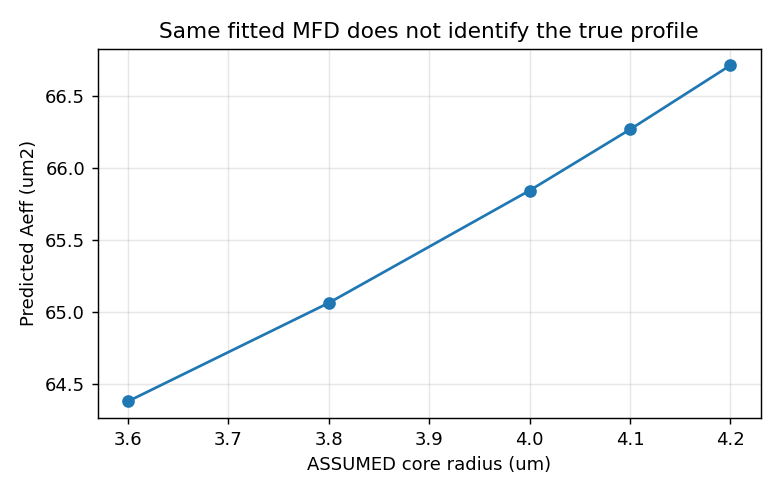

In [9]:
# @title 10. 코어 반경 가정의 비유일성
sens_rows=[]
if run_profile_sensitivity:
    for radius in [3.6,3.8,4.0,4.1,4.2]:
        try:
            ff=calibrated_fiber(radius_um=radius);mm=radial_lp01_aeff(ff)
            sens_rows.append(dict(assumed_radius_um=radius,status='FIT',fitted_delta_n=ff.delta_n,Aeff_um2=mm['Aeff_um2'],D1550=dispersion_lp01(replace(ff,wavelength_um=1.55))))
        except ValueError as err:sens_rows.append(dict(assumed_radius_um=radius,status='NO_SUPPORTED_ROOT'))
sensitivity_df=pd.DataFrame(sens_rows)
if len(sensitivity_df):
    display(sensitivity_df);ok=sensitivity_df[sensitivity_df.status=='FIT']
    fig,ax=plt.subplots(figsize=(6,3.8));ax.plot(ok.assumed_radius_um,ok.Aeff_um2,'o-')
    ax.set(xlabel='ASSUMED core radius (um)',ylabel='Predicted Aeff (um2)',title='Same fitted MFD does not identify the true profile');ax.grid(alpha=.3)
    fig.tight_layout();fig.savefig(RESULT_DIR/'08_Profile_Sensitivity.png',dpi=130);plt.show()


In [10]:
# @title 11. 통과/실패/미검증 판정 및 결과 ZIP
last=radial_df.iloc[-1]
numerical_checks={
 'Radial |neff error| <1e-6':bool(last.neff_abs_error<1e-6),
 'Radial |Aeff error| <1%':bool(abs(last.Aeff_error_pct)<1),
 'Radial |second-moment MFD error| <1%':bool(abs(last.MFD_error_pct)<1),
 'Radial mesh error decreases at every refinement':bool(np.all(np.diff(radial_df.neff_abs_error)<0)),
 'Radial residual <1e-8':bool(last.residual<1e-8),
 'Fixed-spacing domain neff change <1e-7':bool(abs(domain_df.iloc[-1].n_eff-domain_df.iloc[-2].n_eff)<1e-7),
 'Fixed-spacing domain Aeff change <0.1%':bool(abs(domain_df.iloc[-1].Aeff_um2/domain_df.iloc[-2].Aeff_um2-1)<.001),
 'D1550 derivative-step spread <0.01':bool(max(disp_steps.values())-min(disp_steps.values())<.01)}
if run_2d_fem:
    row=fem2d_df.iloc[-1]
    numerical_checks.update({'2D |neff error| <1e-5':bool(row.neff_abs_error<1e-5),
     '2D |Aeff error| <2%':bool(abs(row.Aeff_error_pct)<2),
     '2D |second-moment MFD error| <2%':bool(abs(row.MFD_second_error_pct)<2),
     '2D residual <1e-8':bool(row.residual<1e-8)})
reference_checks={'lambda0 in [1300,1324] nm':bool(1300<=zero_nm<=1324),
 'S0 in [.073,.092] ps/(nm2 km)':bool(.073<=S0<=.092),
 'D1550 in [13.3,18.6] ps/(nm km)':bool(13.3<=D_at1550<=18.6),
 'D1625 in [17.2,23.7] ps/(nm km)':bool(17.2<=D_at1625<=23.7)}
calibration_residual=m1310['MFD_petermann_ii_um']-reference_mfd_um if fit_delta_n_from_mfd else None
not_testable=['actual manufacturer n(r)/trench','actual bending loss at R=10/15 mm','attenuation incl. Rayleigh/absorption',
 'measured cable cutoff','manufacturer Aeff','PMD/birefringence','COMSOL full-vector equivalence']
check_df=pd.DataFrame([dict(group=g,test=k,status='PASS' if v else 'FAIL') for g,c in [('NUMERICAL',numerical_checks),('STANDARD_REFERENCE_ONLY',reference_checks)] for k,v in c.items()])
display(check_df);print('수치 검사:',sum(numerical_checks.values()),'/',len(numerical_checks),'규격 수치 참고:',sum(reference_checks.values()),'/',len(reference_checks))
print('독립 제품 검증: 없음. MFD 보정 잔차:',calibration_residual)
frames={'radial_mesh_table.csv':radial_df,'radial_domain_table.csv':domain_df,'dispersion_spectrum.csv':Dband_df,'checks.csv':check_df}
if len(fem2d_df):frames['fem2d_mesh_table.csv']=fem2d_df
if len(sensitivity_df):frames['profile_sensitivity.csv']=sensitivity_df
for name,frame in frames.items():frame.to_csv(RESULT_DIR/name,index=False)
pd.DataFrame([results]).to_csv(RESULT_DIR/'summary.csv',index=False)
record=dict(schema_version=1,created_utc=datetime.now(timezone.utc).isoformat(),model='calibrated scalar circular step-index G.657.A1 surrogate',
 parameters_and_results=results,numerical_checks=numerical_checks,reference_checks=reference_checks,
 numerical_passed=sum(numerical_checks.values()),numerical_total=len(numerical_checks),
 reference_passed=sum(reference_checks.values()),reference_total=len(reference_checks),
 calibration_residual_um=calibration_residual,not_testable=not_testable,dispersion_step_convergence=disp_steps,
 radial_mesh=json.loads(radial_df.to_json(orient='records',double_precision=15)),radial_domain=json.loads(domain_df.to_json(orient='records',double_precision=15)),
 fem2d=json.loads(fem2d_df.to_json(orient='records',double_precision=15)),sensitivity=json.loads(sensitivity_df.to_json(orient='records',double_precision=15)),
 environment=dict(python=sys.version,numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=plt.matplotlib.__version__,platform=platform.platform()),
 sources=dict(LS_2025_brochure='https://fliphtml5.com/plzsm/rgkq/20250925_%ED%86%B5%EC%8B%A0_%EB%B8%8C%EB%A1%9C%EC%85%94/',ITU_G657_2024='https://www.itu.int/epublications/publication/itu-t-g-657-2024-08-characteristics-of-a-bending-loss-insensitive-single-mode-optical-fibre-and-cable'),
 source_note='Numerical methods transcribed from existing M7 and G654E benchmark; embedded in this notebook.')
(RESULT_DIR/'summary.json').write_text(json.dumps(record,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
report=f"""# G.657.A1 Colab 실행 보고서

- MFD 보정 목표: {reference_mfd_um:.3f} um @1310 nm; 코어 반경 {f.radius_um} um는 가정
- 보정 Delta n: {f.delta_n:.10f}; 분석 파장 {wavelength_nm} nm
- MFD PII @1550 nm: {m1550['MFD_petermann_ii_um']:.6f} um; Aeff1550: {m1550['Aeff_um2']:.6f} um2
- D1550: {D_at1550:.6f}; D1625: {D_at1625:.6f} ps/(nm km)
- lambda0: {zero_nm:.4f} nm; S0: {S0:.7f} ps/(nm2 km)
- gamma1550: {gamma1550:.6f} 1/(W km), assumed n2={n2_m2_per_W} m2/W
- 数値: {sum(numerical_checks.values())}/{len(numerical_checks)} PASS
- 規格参考: {sum(reference_checks.values())}/{len(reference_checks)} within reference ranges
- 独立製品認証: NONE. Bending loss, attenuation, actual profile and cable cutoff are NOT validated.

## 수치 검사
""".replace('数値','수치 검사').replace('規格参考','규격 수치 참고').replace('独立製品認証','독립 제품 검증')
for k,v in numerical_checks.items():report+=f"- {'PASS' if v else 'FAIL'}: {k}\n"
(RESULT_DIR/'EXECUTION_REPORT.md').write_text(report,encoding='utf-8')
zipname=Path('G657A1_Colab_Results.zip')
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(RESULT_DIR.iterdir()):
        if file.is_file():z.write(file,arcname='G657A1_Colab_Results/'+file.name)
print('현재 실행의 결과만 ZIP에 포함:',zipname.resolve());display(FileLink(str(zipname)))
# Colab에서 다운로드하려면 주석 해제:
# from google.colab import files
# files.download(str(zipname))


수치 검사: 11 / 12 규격 수치 참고: 4 / 4
독립 제품 검증: 없음. MFD 보정 잔차: 1.5631940186722204e-13
현재 실행의 결과만 ZIP에 포함: /workspace/scratch/2a1494642f29/repo/COMSOL/g657a1_validation/G657A1_Colab_Results.zip


                      group  ... status
0                 NUMERICAL  ...   PASS
1                 NUMERICAL  ...   PASS
2                 NUMERICAL  ...   PASS
3                 NUMERICAL  ...   PASS
4                 NUMERICAL  ...   PASS
5                 NUMERICAL  ...   PASS
6                 NUMERICAL  ...   PASS
7                 NUMERICAL  ...   PASS
8                 NUMERICAL  ...   FAIL
9                 NUMERICAL  ...   PASS
10                NUMERICAL  ...   PASS
11                NUMERICAL  ...   PASS
12  STANDARD_REFERENCE_ONLY  ...   PASS
13  STANDARD_REFERENCE_ONLY  ...   PASS
14  STANDARD_REFERENCE_ONLY  ...   PASS
15  STANDARD_REFERENCE_ONLY  ...   PASS

[16 rows x 3 columns]

/workspace/scratch/2a1494642f29/repo/COMSOL/g657a1_validation/G657A1_Colab_Results.zip

## 해석 시 주의

수치 시험과 규격 수치 참고 판정은 구분합니다. 규격 범위에 들어가도 **G.657.A1 인증** 또는 제조사 제품의 검증을 의미하지 않습니다. 실패가 나오면 입력과 메시를 검토하고 실패 상태를 보존하십시오. ITU 굽힘 손실 기준은 실제 굽힘 시험 또는 별도로 검증된 방사손실 모델이 필요합니다.

분석 파장을 바꿔도 MFD 보정 기준은 1310 nm로 유지합니다. 같은 MFD에 맞는 단면은 여러 개일 수 있으므로 예측 Aeff·분산·gamma는 가정 의존 값입니다.
